# Ch 02 — End-to-End ML Project (notebook)

`[← 01 ml-landscape]` · **this notebook** · `[03 classification →]`

Runs top-to-bottom in ~2 min on free Colab CPU. Last verified 2026-06-11.

**What you'll build**
- One project, start to finish: California district statistics in, a dollar prediction out, saved as a single file you reload and call on a new district.
- A `Pipeline` + `ColumnTransformer` leakage firewall that imputes, scales, and one-hot encodes without ever letting test data touch a fitted statistic.
- A stratified train/test split, three competing model families judged on one harness, a tuned random forest, and a bootstrap confidence interval on the test metric.
- A leakage bug you watch fabricate a great-looking score on a pure-noise target, then fix in one structural move.

**How this notebook works.** Code cells with a `# TODO` are yours to fill in. Run the cell to grade yourself: `[ ok ]` passed, `[FAIL]` shows what went wrong, `[ -- ]` means not attempted yet. Every exercise has a hint ladder (open only as many rungs as you need) and a folded solution below it. The notebook runs top-to-bottom even if you fill in nothing: the solution cells redefine the functions so the later parts still work. See Ch 00 for the full protocol.


## Before you start

Three questions. Each is answerable after Ch 00 and Ch 01. Answer them before you run a cell.

1. You split a dataset 80/20, fit a `StandardScaler` on the full data first, then split. What did you just leak, and into where? <details><summary>Answer</summary>The scaler learned the mean and std from all rows, including the 20% that becomes your test set. The test set's information leaked into the training-time statistics. Your test score is now optimistic and you can't trust it. The whole "Prepare the data" part exists to make this leak impossible by construction.</details>
2. A model reports a cross-validation RMSE of 0.49 and a test RMSE of 0.47. Is that a problem? <details><summary>Answer</summary>No. Test is slightly *better* than CV, which is normal sampling noise when the splits are clean. A test score much *better* than CV is the alarm: it usually means leakage. A test score much *worse* than CV means overfitting to the validation folds or a distribution shift between split halves.</details>
3. Predict before you run: of California Housing's nine features, which single one will dominate the correlation with house value? <details><summary>Answer</summary>Median income (`MedInc`), at about +0.69. Everything else is below 0.16 in magnitude. Income dominating the signal is the most important thing the EDA tells you, and it is why we stratify the split on income.</details>


## Setup


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
print(f"numpy {np.__version__} · pandas {pd.__version__} · sklearn {sklearn.__version__} · scipy {scipy.__version__}")
if np.__version__ < "2.0":
    print("WARN: this notebook is written for NumPy 2.x; older versions may differ slightly")

numpy 2.2.6 · pandas 2.3.3 · sklearn 1.7.2 · scipy 1.15.3


In [ ]:
import os, random
SEED = 0
FAST = bool(os.environ.get('NB_FAST'))   # CI smoke mode: fewer trees/search iters, same code paths
rng = np.random.default_rng(SEED)         # the one RNG we pass around for reproducible synthesis
random.seed(SEED)

# ── house self-check harness (identical across all chapter notebooks) ──
import numpy as _np

def check(label, test_fn, required=False):
    """Run one self-check. test_fn raises AssertionError (with a teaching
    message) on failure, NotImplementedError if the stub is unfilled.
    required=True is used only in solution cells; it is what CI grades."""
    try:
        test_fn()
    except NotImplementedError:
        if required:
            raise AssertionError(f"{label}: reference solution incomplete")
        print(f"[ -- ] {label}: not attempted yet — fill in the TODO above, then re-run.")
        return False
    except AssertionError as e:
        if required:
            raise
        print(f"[FAIL] {label}: {e}")
        return False
    print(f"[ ok ] {label}")
    return True

def attempted(*vals):
    """Treat None placeholders as 'not attempted'."""
    if any(v is None for v in vals):
        raise NotImplementedError

def check_shape(x, want):
    assert tuple(x.shape) == tuple(want), \
        f"shape {tuple(x.shape)}, expected {tuple(want)} — check your reshape/transpose order"

def check_close(got, want, atol=1e-5, rtol=1e-4, msg=""):
    g, w = _np.asarray(got, dtype=float), _np.asarray(want, dtype=float)
    assert g.shape == w.shape, f"shape {g.shape} vs expected {w.shape}. {msg}"
    bad = ~_np.isclose(g, w, atol=atol, rtol=rtol)
    assert not bad.any(), \
        f"{bad.mean():.2%} of values wrong (max diff {abs(g - w).max():.3g}). {msg}"

> **Note:** seeds make this notebook's printed numbers reproduce on CPU. Library versions, the number of BLAS threads, and the random-forest implementation can shift the last digit or two; the quoted numbers hold for the pinned environment. If your test RMSE is 0.472 and the page says 0.473, you did nothing wrong. We quote RMSE in the dataset's native units, where the target is median house value in units of \$100,000 (so 0.47 is about \$47,000).


## The map

> **Part 1 — Frame and get the data.** Turn "predict house prices" into a task with an input, an output, a metric, and a baseline; load California Housing idempotently and look at its shape.
> **Part 2 — Explore (EDA).** Find the four weird things about this dataset in fifteen minutes: the caps, the skew, the geography, and which feature carries the signal.
> **Part 3 — The split is a decision.** Build a stratified train/test split on binned income and prove it beats a random split on bias; then lock the test set away.
> **Part 4 — The pipeline is the leakage firewall.** Compose imputation, scaling, and one-hot encoding into one `Pipeline` + `ColumnTransformer` that cannot leak, and watch a leak fabricate a score when you step outside it.
> **Part 5 — Select, tune, and analyze.** Compare three model families on one harness, tune the winner, read the residuals, and look at where it fails.
> **Part 6 — Touch the test set once.** Compute the test metric with a bootstrap confidence interval, save the whole pipeline as one artifact, and reload it to predict on a new district.


## Part 1 — Frame and get the data

> **Objectives**
> - State the task as input, output, metric, and baseline before writing model code.
> - Load California Housing through an idempotent, offline loader (no mutable URL).
> - Confirm the shape and dtypes match the data dictionary.


### 1.1 Framing the problem

Three questions, answered before any model. They take thirty minutes and save weeks.

1. **Objective.** Predict the median house value of a California district, accurate enough to flag mispriced listings in an automated valuation pipeline.
2. **Metric and tolerance.** Median absolute error in the target's native units (\$100k) — the median of the per-district absolute errors, robust to the capped-price districts a few wildly-wrong predictions cannot drag it upward. The product team tolerates about \$25k (0.25 in \$100k units); better is the goal. We also track RMSE, which squares errors and so weights the capped-price tail more heavily; the two metrics disagree, and reading both is the point.
3. **Baseline.** A team of human appraisers, entering prices by hand, with a reported **median absolute error of \$30k** (0.30 in \$100k units). Beating \$30k means we contributed something. (We also keep a dumber, secondary floor — a constant predictor that always guesses the training mean — as a sanity check, but it is the naive predictor, not the bar that matters.)

This fixes the rest of the notebook: the task is **supervised regression**, the headline metric is **median absolute error** (with RMSE as a tail-sensitive companion), and the bar to clear is the human-appraiser median AE of \$30k. Because the baseline is stated as a *median AE*, the only model number that legitimately compares against it is the model's own median AE — not its RMSE or MAE. If you cannot answer these three about your own project, stop coding and answer them first.


### 1.2 Get the data, idempotently

`fetch_california_housing` ships with scikit-learn and caches under `data/`. The first call may download a few hundred KB once; every call after is a no-op read from disk. This is the Tier-2 dataset pattern: a built-in loader with an immutable source, not a raw file pulled from a mutable git branch.

> **Caveat:** the chapter prose fetched `ageron/data@main/housing.tgz`. Fetching from a branch (`@main`) is a moving target: the file can change under you and there is no checksum. We use the sklearn loader instead. It carries the same 20,640 districts and the 1990 census features, minus the `ocean_proximity` column and the missing values, which we reconstruct deterministically in 1.3 so the imputation and one-hot lessons stay real.


In [ ]:
from sklearn.datasets import fetch_california_housing

raw = fetch_california_housing(as_frame=True, data_home="data")  # idempotent: cached under data/ after first call
housing = raw.frame.copy()
print(f"shape {housing.shape}")
print(housing.columns.tolist())

shape (20640, 9)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


The nine columns and the target:

| Column | Meaning |
|---|---|
| `MedInc` | median income in the district (tens of thousands of USD) |
| `HouseAge` | median house age in years (capped at 52) |
| `AveRooms` | average rooms per household |
| `AveBedrms` | average bedrooms per household |
| `Population` | district population |
| `AveOccup` | average household occupancy |
| `Latitude` / `Longitude` | district centroid |
| `MedHouseVal` | TARGET: median house value in units of \$100,000 (capped at 5.0) |


In [ ]:
housing.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521


> **Interpretation.** Nine numeric features and one numeric target, 20,640 rows. No string columns yet and no missing values yet. Both of those are realities of messy data, so the next cell puts them back in on purpose, deterministically, so the pipeline we build has something to impute and to encode.


### 1.3 Reconstruct the messy parts (deterministically)

The original Géron CSV had a categorical `ocean_proximity` and a column with missing values. The sklearn version is clean. We add both back with the seeded RNG so the result is identical on every run and the EDA, imputation, and one-hot steps all have real work to do. We derive `ocean_proximity` from longitude bands (the coast runs down the west edge of the state, so longitude is a defensible distance-to-ocean proxy) and knock out about 1% of `AveBedrms` to NaN.


In [ ]:
# derive a categorical from geography: longitude bands as a coast-distance proxy
lon_edges = [-125.0, -122.5, -120.5, -118.0, -113.0]   # west (coast) -> east (inland)
lon_labels = ["NEAR BAY", "<1H OCEAN", "INLAND", "FAR INLAND"]
housing["ocean_proximity"] = pd.cut(housing["Longitude"], bins=lon_edges, labels=lon_labels)

# knock ~1% of AveBedrms to NaN so the imputer has a job (seeded, so it is reproducible)
miss_mask = rng.random(len(housing)) < 0.01
housing.loc[miss_mask, "AveBedrms"] = np.nan

print(housing["ocean_proximity"].value_counts().to_string())
print(f"\nAveBedrms missing: {int(housing['AveBedrms'].isna().sum())} of {len(housing)}")

ocean_proximity
INLAND        7811
<1H OCEAN     6901
FAR INLAND    5080
NEAR BAY       848

AveBedrms missing: 204 of 20640


> **Interpretation.** Four geographic categories with a heavy class imbalance (`NEAR BAY` is rare), and about 204 missing `AveBedrms`. The categorical needs one-hot encoding and the NaNs need imputation, and both must be learned from training data only. That is exactly what the pipeline in Part 4 enforces.

> **Key takeaways**
> - Framing (objective, metric, baseline) comes before code; it decides everything downstream.
> - Idempotent loaders with immutable sources, never a mutable branch URL.
> - Real datasets have categoricals and gaps; we reconstructed them deterministically so the lessons are not theater.


## Part 2 — Explore (EDA)

> **Objectives**
> - Read `info()` and `describe()` for dtypes, gaps, and caps.
> - See the skew in the histograms and the geography in the scatter.
> - Rank features by correlation with the target and confirm income dominates.


### 2.1 Structure: dtypes, gaps, ranges

`info()` tells you dtypes and where the gaps are. `describe()` tells you the ranges, and the ranges are where the surprises hide.


In [ ]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   MedInc           20640 non-null  float64 
 1   HouseAge         20640 non-null  float64 
 2   AveRooms         20640 non-null  float64 
 3   AveBedrms        20436 non-null  float64 
 4   Population       20640 non-null  float64 
 5   AveOccup         20640 non-null  float64 
 6   Latitude         20640 non-null  float64 
 7   Longitude        20640 non-null  float64 
 8   MedHouseVal      20640 non-null  float64 
 9   ocean_proximity  20640 non-null  category
dtypes: category(1), float64(9)
memory usage: 1.4 MB


In [ ]:
housing.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20436.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.48,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


> **Predict:** two columns are *capped*, meaning their max is an artificial ceiling rather than a real measurement. Which two, and how would you spot a cap in `describe()`? <details><summary>Answer</summary>`HouseAge` maxes at exactly 52.0 and `MedHouseVal` maxes at 5.00001 (i.e. \$500,001). A cap shows up as a suspiciously round maximum with many rows piled exactly on it. The target cap matters most: the model can never predict above 5.0, so it will systematically under-predict the most expensive districts.</details>


In [ ]:
# how many districts sit exactly at each cap?
at_age_cap = int((housing["HouseAge"] >= 52.0).sum())
at_val_cap = int((housing["MedHouseVal"] >= 5.0).sum())
print(f"HouseAge at the 52-year cap: {at_age_cap}")
print(f"MedHouseVal at the $500k cap: {at_val_cap}")
assert at_val_cap > 500, "the target cap should trap many districts; if not, the data changed under us"

HouseAge at the 52-year cap: 1273
MedHouseVal at the $500k cap: 992


> **Interpretation.** Over 900 districts are pinned at the target cap. The model's residuals will fan out badly there, because the truth was clipped before we ever saw it. We will see exactly that fan-out in the residual plot in Part 5.


### 2.2 Distributions: the histograms

A single `hist` grid is the fastest way to see skew, caps, and multi-modality at once.


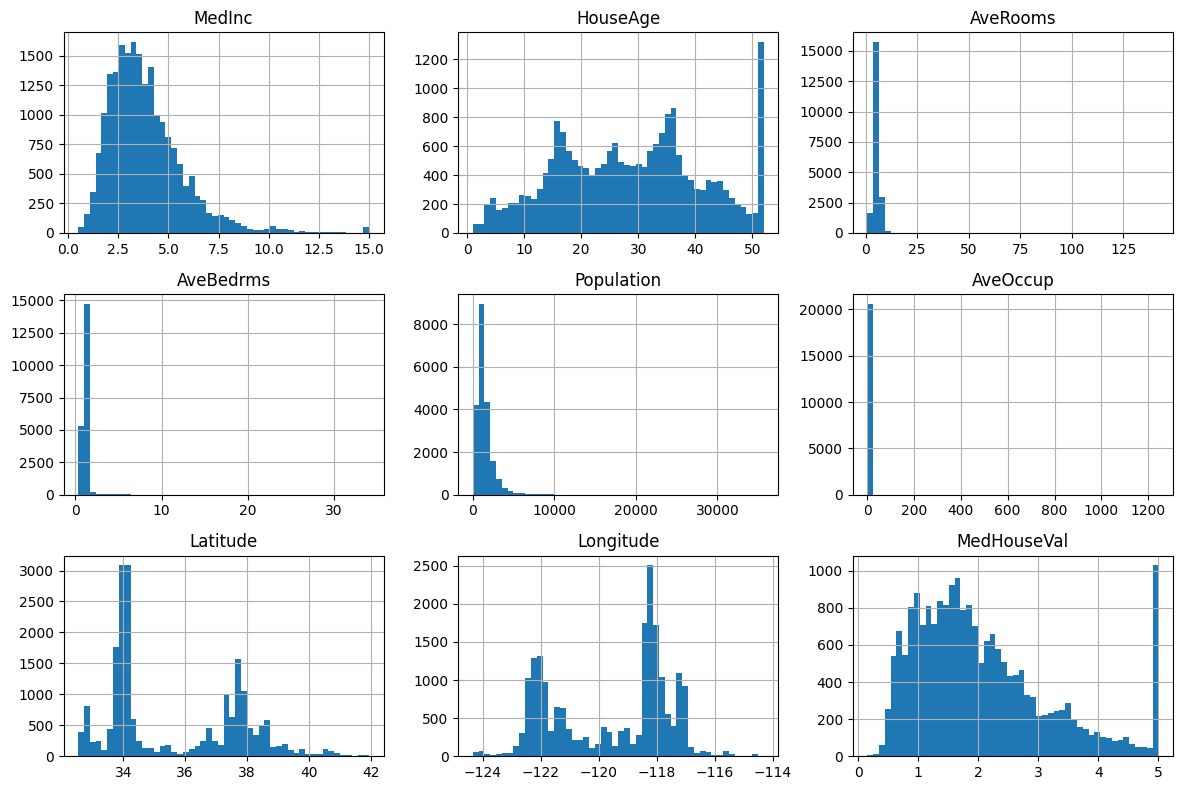

In [ ]:
# viz: one histogram per numeric column
num_only = housing.select_dtypes(include="number")
num_only.hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

> **What is the interpretation of this grid?** <details><summary>Answer</summary>The count-like and average columns (`Population`, `AveRooms`, `AveOccup`) are heavily right-skewed with long tails. `MedInc` is right-skewed and bounded. `HouseAge` and `MedHouseVal` show a spike at their caps. Skew and caps both argue for either a robust metric or a transform; we lead with the robust median AE (the framing's baseline metric) and keep RMSE as a tail-sensitive companion, rather than transforming the target, so the chapter's headline metric stays comparable to the \$30k baseline.</details>


### 2.3 Geography: the scatter that draws California

Plot the districts at their coordinates, sized by population and colored by value. The state appears, and so does the price gradient.


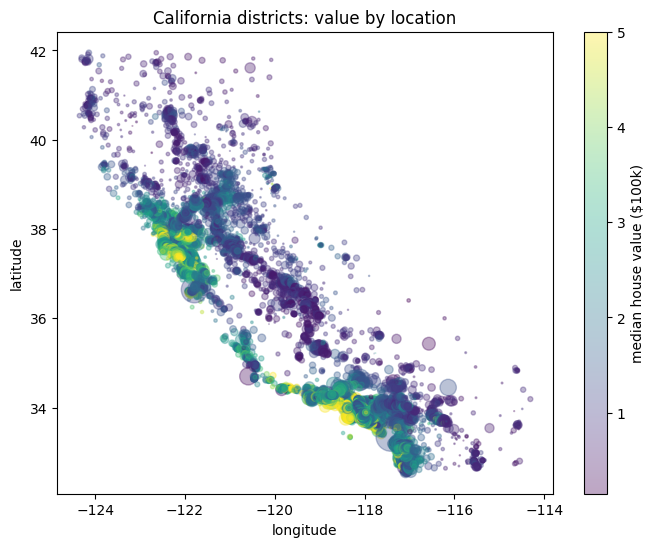

In [ ]:
# viz: geographic scatter, color = value, size = population
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(housing["Longitude"], housing["Latitude"],
                c=housing["MedHouseVal"], cmap="viridis",
                s=housing["Population"] / 80, alpha=0.35)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
fig.colorbar(sc, ax=ax, label="median house value ($100k)")
plt.title("California districts: value by location")
plt.show()

> **Interpretation.** The coastline and the two big metros (the Bay Area in the north, Los Angeles in the south) light up in yellow. Geography carries real signal: coastal and metro districts are worth more. That is why latitude and longitude, weak on their own correlations, still earn their place as features (a tree can split on them jointly).


### Exercise 2.1 — Rank features by correlation with the target

`Difficulty 2/5 · ~8 min`

Fill in `target_corrs(df, target)` returning a pandas `Series` of each numeric column's Pearson correlation with the target, sorted descending, with the target's own self-correlation (1.0) dropped. This is the single most informative line of the whole EDA: it tells you which feature carries the signal.


In [ ]:
def target_corrs(df, target="MedHouseVal"):
    """Pearson correlation of every numeric column with `target`,
    sorted high-to-low, with the target's self-correlation removed.
    Returns a pandas Series indexed by column name."""
    # TODO 1: compute the correlation matrix of the numeric columns (df.corr(numeric_only=True))
    corr = None
    # TODO 2: pull out the target's column/row, sort descending
    series = None
    # TODO 3: drop the target's own entry (its self-correlation is 1.0)
    attempted(corr, series)
    return series.drop(labels=[target])

def _corr_signal():
    s = target_corrs(housing)
    # MedInc must dominate; it is ~+0.69 and everything else is well below it.
    assert s.index[0] == "MedInc", f"top feature was {s.index[0]!r}, expected 'MedInc'"
    assert s.iloc[0] > 0.6, f"top correlation {s.iloc[0]:.2f} should exceed 0.6"
    assert "MedHouseVal" not in s.index, "you left the target's self-correlation in"

check("2.1 income dominates", _corr_signal)

[ -- ] 2.1 income dominates: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>`df.corr(numeric_only=True)` gives a square matrix. Index it by the target name to get one column, then `.sort_values(ascending=False)`.</details>

<details><summary>Hint 2 (pseudocode)</summary>

```python
corr = df.corr(numeric_only=True)
series = corr[target].sort_values(ascending=False)
# the function body already drops the target label for you
```
</details>

<details><summary>Help — "KeyError: 'MedHouseVal'"</summary>You indexed the matrix before sorting, or you sorted the wrong axis. `corr[target]` selects the target's column; that column is a Series you can sort directly.</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines target_corrs; the check below re-verifies the reference.
def target_corrs(df, target="MedHouseVal"):
    corr = df.corr(numeric_only=True)
    series = corr[target].sort_values(ascending=False)
    return series.drop(labels=[target])

check("2.1 income dominates", _corr_signal, required=True)
print(target_corrs(housing).round(3).to_string())

[ ok ] 2.1 income dominates
MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144


> **Interpretation.** `MedInc` at about +0.69, then a steep drop. No other raw feature breaks 0.16. This is the diagnostic that tells you a linear model on income alone is a real baseline, and that the gains will come from features and models that can combine the weak signals (geography, occupancy) nonlinearly.


### Exercise 2.2 — Engineer a ratio feature that beats its parents

`Difficulty 2/5 · ~8 min`

Raw counts are often weaker than ratios. Fill in `add_bedroom_ratio(df)` to add a `bedrooms_per_room = AveBedrms / AveRooms` column. Then we check that its correlation magnitude with the target exceeds `AveBedrms`'s own. Engineered features earning their keep is a theme that returns in Part 5's importances.

Harder: also add `rooms_per_person = AveRooms / AveOccup` and print its correlation.


In [ ]:
def add_bedroom_ratio(df):
    """Return a copy of df with a new column bedrooms_per_room = AveBedrms / AveRooms."""
    out = df.copy()
    # TODO 1: out["bedrooms_per_room"] = AveBedrms divided by AveRooms
    out["bedrooms_per_room"] = None
    attempted(out["bedrooms_per_room"].iloc[0])
    return out

def _ratio_beats_parent():
    enriched = add_bedroom_ratio(housing)
    c = enriched.corr(numeric_only=True)["MedHouseVal"]
    ratio_strength = abs(c["bedrooms_per_room"])
    parent_strength = abs(c["AveBedrms"])
    assert ratio_strength > parent_strength, (
        f"bedrooms_per_room |corr|={ratio_strength:.3f} should beat "
        f"AveBedrms |corr|={parent_strength:.3f}; check your division order")

check("2.2 ratio beats parent", _ratio_beats_parent)

[ -- ] 2.2 ratio beats parent: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>Two columns divide elementwise in pandas: `df["a"] / df["b"]` returns a new Series aligned by index.</details>

<details><summary>Hint 2 (the line)</summary>`out["bedrooms_per_room"] = out["AveBedrms"] / out["AveRooms"]`. Bedrooms on top, rooms on the bottom.</details>

<details><summary>Help — the correlation came out NaN</summary>You divided by a column that contains zeros, or you left the NaNs from 1.3 in `AveBedrms`. pandas `.corr` drops NaN pairs, so a NaN result usually means a divide-by-zero produced `inf`. Check `AveRooms.min()`.</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines add_bedroom_ratio; the check below re-verifies the reference.
def add_bedroom_ratio(df):
    out = df.copy()
    out["bedrooms_per_room"] = out["AveBedrms"] / out["AveRooms"]
    return out

check("2.2 ratio beats parent", _ratio_beats_parent, required=True)
enriched = add_bedroom_ratio(housing)
c = enriched.corr(numeric_only=True)["MedHouseVal"]
print(f"AveBedrms        corr = {c['AveBedrms']:+.3f}")
print(f"bedrooms_per_room corr = {c['bedrooms_per_room']:+.3f}")
# Harder: rooms per person
print(f"rooms_per_person  corr = {(enriched['AveRooms']/enriched['AveOccup']).corr(enriched['MedHouseVal']):+.3f}")

[ ok ] 2.2 ratio beats parent
AveBedrms        corr = -0.047
bedrooms_per_room corr = -0.255
rooms_per_person  corr = +0.209


> **Interpretation.** The ratio carries more signal than its parent count, which is the whole argument for feature engineering. We will fold this kind of ratio into the pipeline as a custom transformer in Part 4 so it is computed the same way at train time and at inference time.

> **Key takeaways**
> - `info` and `describe` first; caps and gaps live in the ranges.
> - Histograms reveal skew; the geographic scatter reveals that location is signal.
> - `MedInc` dominates the correlation ranking; engineered ratios can beat raw counts.


## Part 3 — The split is a decision

> **Objectives**
> - Bin income into strata and split so the strata are preserved.
> - Quantify how a random split biases the income mix versus a stratified one.
> - Lock the test set away and not look at it again until Part 6.


### 3.1 Why stratify on income

A random split is fine when the data is large and well mixed. But income is so predictive here that if the train and test halves end up with different income mixes, the test score measures the mix as much as the model. The fix is to bin income into a few categories and sample each category proportionally into both halves. We bin with the same edges Géron uses, chosen so each bucket has enough districts to be stable.


In [ ]:
# income strata: edges chosen so each bucket is populated (Géron's bins)
income_bins = [0.0, 1.5, 3.0, 4.5, 6.0, np.inf]
housing["income_cat"] = pd.cut(housing["MedInc"], bins=income_bins, labels=[1, 2, 3, 4, 5])
print(housing["income_cat"].value_counts().sort_index().to_string())

income_cat
1     822
2    6581
3    7236
4    3639
5    2362


> **Interpretation.** Five strata, with the middle buckets fattest and the extremes thin. The thin extreme buckets are exactly the ones a random split can under-sample by chance, biasing the evaluation.


### Exercise 3.1 — A stratified split that preserves the income mix

`Difficulty 3/5 · ~15 min`

Fill in `make_split(df, strat_col, test_size, seed)` using `StratifiedShuffleSplit` to return `(train_df, test_df)`, with the helper `strat_col` dropped from both. The seed is fixed so the checks know what to expect, the same reproducibility discipline you used in Ch 00. We then verify the test set's stratum proportions match the full data to within a tight tolerance.


In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

def make_split(df, strat_col, test_size=0.2, seed=SEED):
    """Stratified train/test split. Returns (train_df, test_df) with strat_col dropped."""
    # TODO 1: build StratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    splitter = None
    # TODO 2: get the single (train_idx, test_idx) pair: next(splitter.split(df, df[strat_col]))
    train_idx, test_idx = None, None
    attempted(splitter, train_idx, test_idx)
    train_df = df.iloc[train_idx].drop(columns=strat_col)
    test_df = df.iloc[test_idx].drop(columns=strat_col)
    return train_df, test_df

def _strat_preserved():
    tr, te = make_split(housing, "income_cat", test_size=0.2, seed=SEED)
    # recompute strata on the test split and compare proportions to the full data
    full_p = housing["income_cat"].value_counts(normalize=True).sort_index()
    te_cat = pd.cut(te["MedInc"], bins=income_bins, labels=[1, 2, 3, 4, 5])
    te_p = te_cat.value_counts(normalize=True).sort_index()
    max_diff = float((full_p - te_p).abs().max())
    assert max_diff < 0.005, (
        f"max stratum-proportion drift {max_diff:.4f} is too large; "
        "a stratified split should keep it near zero (a random split would be ~10x worse)")
    assert "income_cat" not in tr.columns, "you forgot to drop the income_cat helper column"

check("3.1 stratified split", _strat_preserved)

[ -- ] 3.1 stratified split: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>`StratifiedShuffleSplit` yields index arrays, not data. You give `.split` the frame and the stratification column, and it hands back `(train_idx, test_idx)`. With `n_splits=1` there is exactly one pair, so `next(...)` is the idiom.</details>

<details><summary>Hint 2 (pseudocode)</summary>

```python
splitter = StratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
train_idx, test_idx = next(splitter.split(df, df[strat_col]))
# the function body already does the .iloc and the column drop
```
</details>

<details><summary>Help — "Found input variables with inconsistent numbers of samples"</summary>You passed the stratification column as a 2D frame instead of a 1D Series, or you passed `df` twice. The first argument is the data to index, the second is the 1D strata: `splitter.split(df, df[strat_col])`.</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines make_split; the check below re-verifies the reference.
def make_split(df, strat_col, test_size=0.2, seed=SEED):
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_idx, test_idx = next(splitter.split(df, df[strat_col]))
    train_df = df.iloc[train_idx].drop(columns=strat_col)
    test_df = df.iloc[test_idx].drop(columns=strat_col)
    return train_df, test_df

check("3.1 stratified split", _strat_preserved, required=True)
strat_train, strat_test = make_split(housing, "income_cat", test_size=0.2, seed=SEED)
print(f"train {strat_train.shape} · test {strat_test.shape}")

[ ok ] 3.1 stratified split
train (16512, 10) · test (4128, 10)


### 3.2 How biased would a random split have been?

Claim from the prose: a random split skews the income mix more than a stratified one. Let us not take that on faith. We compute the per-stratum proportion error for both kinds of split and compare. This is the spanish-inquisition rule: a claim that can be an assert should be one.


In [ ]:
from sklearn.model_selection import train_test_split

def stratum_error(test_subset):
    full_p = housing["income_cat"].value_counts(normalize=True).sort_index()
    cats = pd.cut(test_subset["MedInc"], bins=income_bins, labels=[1, 2, 3, 4, 5])
    te_p = cats.value_counts(normalize=True).sort_index()
    return float((full_p - te_p).abs().sum())   # total absolute proportion error

# random split (same size, same seed) vs the stratified test set from 3.1
rand_train, rand_test = train_test_split(housing, test_size=0.2, random_state=SEED)
strat_err = stratum_error(strat_test)
rand_err = stratum_error(rand_test)
print(f"stratified split total stratum error: {strat_err:.4f}")
print(f"random split     total stratum error: {rand_err:.4f}")
assert strat_err < rand_err, "stratifying should reduce stratum drift; if not, check the bins"
print(f"the random split is {rand_err / max(strat_err, 1e-9):.1f}x more biased on the income mix")

stratified split total stratum error: 0.0004
random split     total stratum error: 0.0143
the random split is 37.0x more biased on the income mix


> **Interpretation.** The random split distorts the income mix several times more than the stratified one. On a small test set that distortion becomes test-score noise you cannot diagnose. The general rule: if a feature is predictive enough that imbalance in it would bias evaluation, stratify on a binned version of it. Time series get a different rule entirely, a chronological split, never random.

> **Caveat:** drop the `income_cat` helper before modeling (the split already did). It was scaffolding for the split, not a feature. Leaving engineered split-helpers in the feature matrix is a quiet way to leak the very structure you split on.


> **Key takeaways**
> - Stratify on a binned version of any feature predictive enough to bias evaluation.
> - We proved the random split was several times more biased, rather than asserting it.
> - The test set (`strat_test`) is now sealed; we do not touch it until Part 6.


## Part 4 — The pipeline is the leakage firewall

> **Objectives**
> - Separate features from target, and name the numeric vs categorical columns.
> - Build a custom transformer for the engineered ratios that runs inside the pipeline.
> - Compose imputation, scaling, encoding into one `ColumnTransformer` that cannot leak.
> - Watch a leak fabricate a score on a noise target, then close it structurally.


### 4.1 Separate features and target

The target never goes through the feature pipeline. We split it off first, on both halves.


In [ ]:
X_train = strat_train.drop(columns="MedHouseVal")
y_train = strat_train["MedHouseVal"].copy()
X_test = strat_test.drop(columns="MedHouseVal")
y_test = strat_test["MedHouseVal"].copy()

num_columns = ["MedInc", "HouseAge", "AveRooms", "AveBedrms",
               "Population", "AveOccup", "Latitude", "Longitude"]
cat_columns = ["ocean_proximity"]
print(f"X_train {X_train.shape} · numeric {len(num_columns)} · categorical {len(cat_columns)}")

X_train (16512, 9) · numeric 8 · categorical 1


### Exercise 4.1 — A custom transformer for the ratio feature

`Difficulty 3/5 · ~15 min`

A pipeline stage is any object with `fit` and `transform`. To compute the `bedrooms_per_room` ratio the same way at train and inference time, wrap it in a transformer. Fill in `RatioAdder.transform` to append the ratio column. The transformer receives a NumPy array (the `ColumnTransformer` passes arrays), and `bedrooms_idx` / `rooms_idx` tell it which columns to divide.

The micro-demo below feeds a 2-row toy array with hand-checkable values, so you can verify the output before touching real data.


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class RatioAdder(BaseEstimator, TransformerMixin):
    """Append AveBedrms / AveRooms as a new last column."""
    def __init__(self, bedrooms_idx=3, rooms_idx=2):
        self.bedrooms_idx = bedrooms_idx
        self.rooms_idx = rooms_idx
    def fit(self, X, y=None):
        return self  # stateless: nothing to learn, so nothing to leak
    def transform(self, X):
        X = np.asarray(X, dtype=float)
        # TODO 1: ratio = column bedrooms_idx divided by column rooms_idx
        ratio = None
        attempted(ratio)
        # TODO 2: stack ratio as a new last column (np.c_[X, ratio])
        return np.c_[X, ratio]

def _ratio_adder_toy():
    # toy: 2 rows, 4 cols [rooms_idx=2, bedrooms_idx=3] -> ratio = col3/col2
    toy = np.array([[0., 0., 4., 1.],     # 1/4 = 0.25
                    [0., 0., 5., 2.]])     # 2/5 = 0.40
    out = RatioAdder(bedrooms_idx=3, rooms_idx=2).fit_transform(toy)
    assert out.shape == (2, 5), f"expected one new column -> shape (2,5), got {out.shape}"
    check_close(out[:, -1], [0.25, 0.40], msg="ratio = bedrooms/rooms: 1/4 and 2/5")

check("4.1 RatioAdder toy", _ratio_adder_toy)

[ -- ] 4.1 RatioAdder toy: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>Index a 2D NumPy array's column with `X[:, j]`. The ratio is `X[:, bedrooms_idx] / X[:, rooms_idx]`. `np.c_[X, ratio]` glues a column on the right.</details>

<details><summary>Hint 2 (pseudocode)</summary>

```python
ratio = X[:, self.bedrooms_idx] / X[:, self.rooms_idx]
return np.c_[X, ratio]
```
</details>

<details><summary>Help — "could not broadcast" or the shape is wrong</summary>`np.c_[X, ratio]` needs `ratio` to be 1D of length `n_rows`. If you wrote `X[:, j:j+1]` you got a 2D column; either is fine for `np.c_`, but mixing a 2D `X` with a 0D scalar ratio (from using the wrong index) fails. Print `ratio.shape`.</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines RatioAdder.transform; the check below re-verifies the reference.
class RatioAdder(BaseEstimator, TransformerMixin):
    def __init__(self, bedrooms_idx=3, rooms_idx=2):
        self.bedrooms_idx = bedrooms_idx
        self.rooms_idx = rooms_idx
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float)
        ratio = X[:, self.bedrooms_idx] / X[:, self.rooms_idx]
        return np.c_[X, ratio]

check("4.1 RatioAdder toy", _ratio_adder_toy, required=True)
print("RatioAdder verified on the toy input")

[ ok ] 4.1 RatioAdder toy
RatioAdder verified on the toy input


> **Note:** `RatioAdder` is stateless, its `fit` learns nothing, so it cannot leak. The stages that *do* learn (the imputer's median, the scaler's mean and std) are the dangerous ones, and the pipeline is what guarantees they only ever see training rows.


### 4.2 Compose the firewall

The numeric branch: impute missing values with the median, append the ratio, then scale. The categorical branch: one-hot encode `ocean_proximity`. A `ColumnTransformer` routes each set of columns to its branch and concatenates the results. The whole thing exposes one `fit_transform` (for train) and one `transform` (for test). You fit on train, transform test. You cannot accidentally do otherwise.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # learns the median from TRAIN only
    ("ratios", RatioAdder()),                        # stateless ratio feature
    ("scale", StandardScaler()),                     # learns mean/std from TRAIN only
])

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_columns),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_columns),  # unseen categories -> all-zero, no crash
])

X_train_prepared = full_pipeline.fit_transform(X_train)   # fit_transform on TRAIN
X_test_prepared = full_pipeline.transform(X_test)         # transform (not fit) on TEST
print(f"prepared train {X_train_prepared.shape} · prepared test {X_test_prepared.shape}")

prepared train (16512, 13) · prepared test (4128, 13)


> **Interpretation.** Eight numeric columns plus one engineered ratio (nine) plus four one-hot categories gives thirteen prepared columns. The train and test column counts match, which is the first thing to check after any `ColumnTransformer`: a mismatch means a category appeared in one half and not the other, and `handle_unknown="ignore"` is what keeps that from crashing inference.


In [ ]:
# the imputer's learned median came from train only; confirm it is a fitted statistic, not a global one
learned_median = full_pipeline.named_transformers_["num"].named_steps["impute"].statistics_
print("imputer medians (per numeric column), learned from train:")
print(np.round(learned_median, 3))

imputer medians (per numeric column), learned from train:
[ 3.5340e+00  2.9000e+01  5.2260e+00  1.0490e+00  1.1670e+03  2.8220e+00
  3.4250e+01 -1.1849e+02]


> **Notice that** the imputer stored one median per numeric column, and those medians were computed on the training rows alone. When `transform` runs on the test set, it reuses these stored medians; it never recomputes them from test data. That is the leak, sealed.


### 4.3 A deliberate failure: leakage fabricates a score

Here is the bug the firewall prevents, staged so you feel it. Take a target that is **pure noise**, unrelated to any feature. A clean evaluation must report no predictive power. But if you select the "best" features using the whole dataset *before* cross-validating, the selection peeks at the held-out folds and fabricates a score. We run the broken version first, see the lie, then fix it with one structural change.


In [ ]:
# scale-up: a small noise dataset where the TRUE signal is zero, so any positive score is fake
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

rng_leak = np.random.default_rng(SEED)           # local RNG so this demo never perturbs the main run
n_demo, p_demo = 100, 2000
X_noise = rng_leak.normal(size=(n_demo, p_demo))
y_noise = rng_leak.normal(size=n_demo)           # target is independent noise: true R^2 is ~0

# BROKEN: pick the 20 features most correlated with y using ALL the data, THEN cross-validate
selector = SelectKBest(f_regression, k=20).fit(X_noise, y_noise)   # <- peeks at every row, including holdout folds
X_selected = selector.transform(X_noise)
leaked_r2 = cross_val_score(LinearRegression(), X_selected, y_noise, scoring="r2", cv=5).mean()
print(f"[broken] cross-validated R^2 after leaky feature selection: {leaked_r2:.3f}")

[broken] cross-validated R^2 after leaky feature selection: 0.405


> **Interpretation.** A model predicting pure noise just reported a clearly positive R². It is entirely fake: the feature selection looked at the same rows the cross-validation later "held out", so the chosen features were tuned to those folds. This is precisely how a leaked test score lies, and why a test score that looks *too good* is an alarm, not a celebration.


In [ ]:
# FIXED: put the selection INSIDE the pipeline, so it refits on each CV training fold only
clean_pipe = Pipeline([
    ("select", SelectKBest(f_regression, k=20)),   # now fit only on each fold's training rows
    ("lr", LinearRegression()),
])
clean_r2 = cross_val_score(clean_pipe, X_noise, y_noise, scoring="r2", cv=5).mean()
print(f"[fixed]  cross-validated R^2 with selection inside the pipeline: {clean_r2:.3f}")
assert clean_r2 < leaked_r2, "the fixed pipeline must report a worse (honest) score than the leaky one"
print("the honest score is near zero (often negative): correct, because the target was noise")

[fixed]  cross-validated R^2 with selection inside the pipeline: -0.133
the honest score is near zero (often negative): correct, because the target was noise


> **Interpretation.** The fix is not a flag or a parameter; it is structure. Once the selection lives inside the pipeline, cross-validation refits it on each fold's training rows alone, and the score collapses to honest near-zero. Every preprocessing step that *learns* anything (a median, a mean, a vocabulary, a feature ranking, a PCA basis) must be a pipeline stage. That is the entire reason `Pipeline` + `ColumnTransformer` exists.

> **Common confusion:** "but my real pipeline above used `fit_transform` on the whole training set, isn't that the same leak?" No. The training set is allowed to see itself. The leak is when the *test* (or CV holdout) influences a fitted statistic. Fitting on all of `X_train` is fine; the firewall is that `X_test` only ever meets `transform`.

> **Key takeaways**
> - Any step that learns a statistic must be a pipeline stage, or it can leak.
> - The `ColumnTransformer` routes columns to branches and concatenates; `fit_transform` train, `transform` test.
> - We watched leakage fabricate R² on a noise target, then closed it with one structural move.


## Part 5 — Select, tune, and analyze

> **Objectives**
> - Compare three model families on one cross-validation harness.
> - Tune the winner with randomized search and read its feature importances.
> - Plot residuals and find where the model fails (the cap, the tails).


### 5.1 One harness, three model families

Wrap the preprocessing and a model into one estimator so cross-validation re-runs the whole pipeline on each fold (no leak). Score with negative RMSE so larger is better in sklearn's convention, then flip the sign for reporting. We compare linear regression, a single decision tree, and a random forest.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

CV = 3                                  # 3-fold keeps the chapter fast; 5 is the usual default
N_TREES = 30 if FAST else 80            # forest size: smaller in CI smoke mode, same code path

def cv_rmse(model, X, y, cv=CV):
    """Mean and std of RMSE across cv folds (sklearn scores negative RMSE, we flip it)."""
    scores = cross_val_score(model, X, y, scoring="neg_root_mean_squared_error", cv=cv)
    rmse = -scores
    return rmse.mean(), rmse.std()

candidates = {
    "LinearRegression": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(random_state=SEED),
    "RandomForest": RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=-1),
}
cv_results = {}
for name, model in candidates.items():
    est = Pipeline([("prep", full_pipeline), ("model", model)])
    m, s = cv_rmse(est, X_train, y_train)
    cv_results[name] = m
    print(f"{name:18s} CV RMSE = {m:.3f} ± {s:.3f}")

LinearRegression   CV RMSE = 0.716 ± 0.009


DecisionTree       CV RMSE = 0.759 ± 0.005


RandomForest       CV RMSE = 0.522 ± 0.002


> **Predict:** which family wins, and why is the single decision tree the worst? <details><summary>Answer</summary>The random forest wins (RMSE ~0.52 vs ~0.72 linear, ~0.76 single tree). The single tree overfits: it can memorize the training folds (near-perfect train fit) but generalizes worse than even the linear model. The forest averages many decorrelated trees, cancelling that variance. This is the chapter's central lesson: the gap between model *families* (here ~0.24 RMSE) dwarfs the gap tuning will buy (a few hundredths). Pick the family before you tune.</details>


In [ ]:
# assert the lesson rather than asserting it in prose
assert cv_results["RandomForest"] < cv_results["LinearRegression"], "forest should beat linear here"
assert cv_results["RandomForest"] < cv_results["DecisionTree"], "forest should beat the single tree"
best_family = min(cv_results, key=cv_results.get)
print(f"best family: {best_family} at CV RMSE {cv_results[best_family]:.3f}")

best family: RandomForest at CV RMSE 0.522


### Exercise 5.1 — The naive predictor (a secondary sanity floor)

`Difficulty 1/5 · ~5 min`

Two baselines live in this chapter, and it pays to keep them straight. The bar that *matters* is the framing's human-appraiser **median AE of \$30k** (0.30 in \$100k units); we compare the model's median AE against it when we touch the test set in Part 6. This exercise builds the *secondary, naive* floor: the RMSE you get by predicting the training mean for every row. It is the dumbest model that still respects the data — a sanity check, not the baseline to beat. Fill in `constant_baseline_rmse(y_train, y_eval)`: the RMSE of always guessing the training mean on `y_eval`.


In [ ]:
def constant_baseline_rmse(y_train, y_eval):
    """RMSE of always predicting the TRAIN mean on y_eval (a numpy array or Series)."""
    y_train = np.asarray(y_train, dtype=float)
    y_eval = np.asarray(y_eval, dtype=float)
    # TODO 1: guess = the mean of y_train (a single number)
    guess = None
    attempted(guess)
    # TODO 2: rmse = sqrt(mean((y_eval - guess)**2))
    return float(np.sqrt(np.mean((y_eval - guess) ** 2)))

def _baseline_sane():
    # on the training set, the constant baseline RMSE equals the train std (population form)
    b = constant_baseline_rmse(y_train, y_train)
    expected = float(np.std(np.asarray(y_train, dtype=float)))
    check_close(b, expected, atol=1e-6, msg="constant-mean RMSE on train == population std of train")
    # and the random forest must beat it comfortably
    assert cv_results["RandomForest"] < b, (
        f"forest CV RMSE {cv_results['RandomForest']:.3f} should beat the baseline {b:.3f}")

check("5.1 constant baseline", _baseline_sane)

[ -- ] 5.1 constant baseline: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>The constant that minimizes squared error is the mean. Compute it on train, broadcast it against every eval target, square the gaps, average, square-root.</details>

<details><summary>Hint 2 (the line)</summary>`guess = y_train.mean()`. The function already does the RMSE with that guess.</details>

<details><summary>Help — "the train-set RMSE didn't equal the std"</summary>RMSE of the mean equals the *population* std (divide by N), which is `np.std(...)` with default `ddof=0`. pandas `.std()` uses `ddof=1` (divide by N-1) and will be slightly larger. The check uses `np.std`, so use the mean of `y_train`, not its std, as your guess.</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines constant_baseline_rmse; the check below re-verifies the reference.
def constant_baseline_rmse(y_train, y_eval):
    y_train = np.asarray(y_train, dtype=float)
    y_eval = np.asarray(y_eval, dtype=float)
    guess = y_train.mean()
    return float(np.sqrt(np.mean((y_eval - guess) ** 2)))

check("5.1 constant baseline", _baseline_sane, required=True)
base = constant_baseline_rmse(y_train, y_train)
print(f"naive predictor RMSE (guess train mean): {base:.3f}   <- secondary sanity floor")
print(f"random forest CV RMSE:                   {cv_results['RandomForest']:.3f}  "
      f"({(1 - cv_results['RandomForest']/base):.0%} better than guessing the mean)")
print("the bar that MATTERS is the $30k human-appraiser MEDIAN AE; we test it in Part 6")

[ ok ] 5.1 constant baseline
naive predictor RMSE (guess train mean): 1.155   <- secondary sanity floor
random forest CV RMSE:                   0.522  (55% better than guessing the mean)
the bar that MATTERS is the $30k human-appraiser MEDIAN AE; we test it in Part 6


> **Interpretation.** The forest cuts the error roughly in half versus the naive mean-guess (RMSE ~0.52 vs ~1.15). Clearing the naive floor is necessary but cheap — it only proves the model learned *something*. The real bar is the human-appraiser **median AE of \$30k** from the framing, and we compare the model's median AE (not its RMSE) against it once, on the test set, in Part 6. Keep the two baselines distinct: the mean-guess RMSE is the naive sanity floor; the \$30k median AE is the baseline to beat.


### 5.2 Tune the winner with randomized search

Grid search enumerates every combination; randomized search samples from distributions and is more efficient when you do not know the right ranges. We wrap the full pipeline so each search candidate is cross-validated end to end (preprocessing included, no leak). The double-underscore in `model__n_estimators` reaches into the `model` step of the pipeline.


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

N_ITER = 4 if FAST else 8               # search budget: tiny in CI, modest otherwise
param_dist = {
    "model__n_estimators": randint(40, 120),   # number of trees
    "model__max_features": randint(2, 8),       # features considered per split (decorrelates trees)
}
rf_pipe = Pipeline([("prep", full_pipeline),
                    ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))])
search = RandomizedSearchCV(
    rf_pipe, param_dist, n_iter=N_ITER, cv=CV,
    scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
print(f"best params: {search.best_params_}")
print(f"best CV RMSE: {-search.best_score_:.3f}  (untuned forest was {cv_results['RandomForest']:.3f})")

best params: {'model__max_features': 5, 'model__n_estimators': 107}
best CV RMSE: 0.497  (untuned forest was 0.522)


> **Interpretation.** Tuning shaves a few hundredths off the RMSE. Real, but small, and far smaller than the ~0.24 the random forest already won over linear regression by being the right family. Internalize the ratio: most practitioners over-invest in hyperparameter search and under-invest in feature engineering and model selection.


### Exercise 5.2 — Read the feature importances

`Difficulty 2/5 · ~10 min`

A fitted forest exposes `feature_importances_`, one number per *prepared* column. Fill in `top_importances(search, feature_names, k)` to pair the importances with their names and return the top `k` as a list of `(name, importance)` tuples, highest first. We then verify income is the single most important feature, matching the EDA.


In [ ]:
# assemble the prepared feature names: numeric + the engineered ratio + the one-hot categories
ohe = full_pipeline.named_transformers_["cat"]
cat_feature_names = list(ohe.get_feature_names_out(cat_columns))
prepared_names = num_columns + ["bedrooms_per_room"] + cat_feature_names
print(f"{len(prepared_names)} prepared features:", prepared_names)

def top_importances(search, feature_names, k=5):
    """Return the top-k (name, importance) tuples from the fitted forest, highest first."""
    importances = search.best_estimator_.named_steps["model"].feature_importances_
    assert len(importances) == len(feature_names), (
        f"{len(importances)} importances vs {len(feature_names)} names; "
        "your prepared_names list is out of sync with the pipeline output")
    # TODO 1: pair each name with its importance, e.g. list(zip(feature_names, importances))
    pairs = None
    # TODO 2: sort by importance descending and keep the first k
    ranked = None
    attempted(pairs, ranked)
    return [(n, float(v)) for n, v in ranked]

def _income_is_top():
    top = top_importances(search, prepared_names, k=5)
    assert top[0][0] == "MedInc", f"top feature was {top[0][0]!r}, expected 'MedInc'"
    assert all(top[i][1] >= top[i + 1][1] for i in range(len(top) - 1)), "not sorted descending"

check("5.2 income most important", _income_is_top)

13 prepared features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'bedrooms_per_room', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_FAR INLAND', 'ocean_proximity_INLAND', 'ocean_proximity_NEAR BAY']
[ -- ] 5.2 income most important: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>`zip(names, importances)` pairs them. `sorted(pairs, key=lambda p: p[1], reverse=True)` ranks by the importance (the second element of each pair). Slice `[:k]`.</details>

<details><summary>Hint 2 (pseudocode)</summary>

```python
pairs = list(zip(feature_names, importances))
ranked = sorted(pairs, key=lambda p: p[1], reverse=True)[:k]
```
</details>

<details><summary>Help — "AssertionError: 13 importances vs 14 names"</summary>Your `prepared_names` has the wrong count. The numeric branch outputs 8 original columns plus 1 ratio = 9, then the one-hot adds one column per category. Re-run the cell that builds `prepared_names`; the order is numeric, then ratio, then categories.</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines top_importances; the check below re-verifies the reference.
def top_importances(search, feature_names, k=5):
    importances = search.best_estimator_.named_steps["model"].feature_importances_
    pairs = list(zip(feature_names, importances))
    ranked = sorted(pairs, key=lambda p: p[1], reverse=True)[:k]
    return [(n, float(v)) for n, v in ranked]

check("5.2 income most important", _income_is_top, required=True)
for name, imp in top_importances(search, prepared_names, k=8):
    print(f"  {imp:.3f}  {name}")

[ ok ] 5.2 income most important
  0.353  MedInc
  0.121  AveOccup
  0.121  Latitude
  0.112  bedrooms_per_room
  0.103  Longitude
  0.065  AveRooms
  0.049  HouseAge
  0.028  AveBedrms


> **Interpretation.** Income leads by a wide margin, then the geographic coordinates and occupancy. The engineered `bedrooms_per_room` usually places in the middle of the pack, which is the payoff for the work in Exercise 2.2. Three or four features carry most of the signal; the rest are nearly free to drop.


### 5.3 Error analysis: read the residuals

The step most tutorials skip. Predict on the *training* set (we still have not touched test), compute residuals, and look at where the model is wrong. The plot tells you what to fix next.


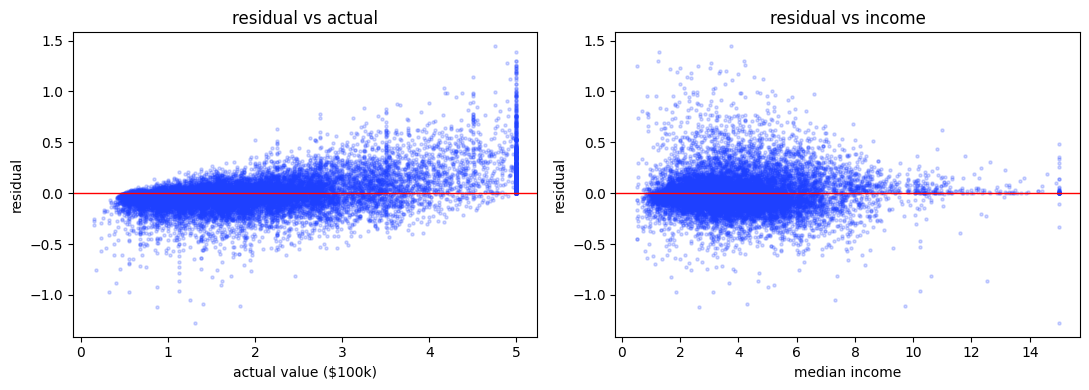

In [ ]:
# train-set residuals (test is still sealed)
y_train_pred = search.best_estimator_.predict(X_train)
residuals = np.asarray(y_train, dtype=float) - y_train_pred

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_train, residuals, s=5, alpha=0.2, color="#1E40FF")
ax[0].axhline(0, color="red", lw=1)
ax[0].set_xlabel("actual value ($100k)"); ax[0].set_ylabel("residual"); ax[0].set_title("residual vs actual")
ax[1].scatter(X_train["MedInc"], residuals, s=5, alpha=0.2, color="#1E40FF")
ax[1].axhline(0, color="red", lw=1)
ax[1].set_xlabel("median income"); ax[1].set_ylabel("residual"); ax[1].set_title("residual vs income")
plt.tight_layout(); plt.show()

> **What is the interpretation of these plots?** <details><summary>Answer</summary>Left: the residuals fan out at the high-value end and there is a hard diagonal wall at the right edge, the fingerprint of the \$500k cap. The truth was clipped before training, so the model cannot help being wrong there; the honest move is to flag capped districts, not to chase them. Right: residuals are roughly centered across income but with more spread at high income, the same heteroscedasticity. Neither pattern is a coding bug; both are properties of the data the framing should acknowledge.</details>


In [ ]:
# confirm the worst errors cluster at the target cap, not scattered at random
worst = np.argsort(np.abs(residuals))[-50:]
frac_at_cap = float((np.asarray(y_train)[worst] >= 4.9).mean())
print(f"of the 50 worst-predicted train districts, {frac_at_cap:.0%} sit near the $500k cap")
assert frac_at_cap > 0.4, "the cap should dominate the worst errors; if not, inspect the residual plot"

of the 50 worst-predicted train districts, 62% sit near the $500k cap


> **Interpretation.** The cap is not a model failure to debug; it is a data property to document. The "iterate" arrow in the workflow points back from here: cap-aware features, a censored-regression model, or simply excluding capped districts from the metric are the principled next moves.

> **Key takeaways**
> - Compare model families on one harness before tuning; the family gap dwarfs the tuning gap.
> - Anchor the model on the baseline's own metric — here the \$30k human-appraiser median AE — and keep the naive mean-guess as a separate sanity floor.
> - Feature importances confirm income leads; residuals reveal the cap as the dominant error source.


## Part 6 — Touch the test set once

> **Objectives**
> - Compute the test metric exactly once, with a bootstrap confidence interval.
> - Save the full pipeline (preprocessing + model) as one artifact.
> - Reload it and predict on a brand-new district.


### 6.1 The test set, once, with a confidence interval

This is the moment the test set is touched, and the only moment. After this number exists, any further change to the pipeline invalidates it: you would be tuning on the test set, which is leakage by another name. A point estimate alone is not enough. "Test RMSE 0.47" means nothing without "± what?", so we attach a 95% confidence interval. We use the bootstrap (resample the test errors with replacement, recompute the metric each time), which makes no distributional assumption about the errors.


### Exercise 6.1 — Bootstrap a confidence interval on the test RMSE

`Difficulty 3/5 · ~15 min`

Fill in `bootstrap_rmse_ci(y_true, y_pred, n_boot, alpha, seed)`. Resample the *indices* with replacement `n_boot` times; for each resample, compute the RMSE on that subset; return the central point estimate and the `(lo, hi)` percentile interval at confidence `1 - alpha`. Pass an explicit seeded RNG so the interval reproduces.

> **Stop and think:** why resample indices rather than resampling `(y_true, y_pred)` pairs directly? <details><summary>Answer</summary>They are the same thing if you keep the pairs aligned. Resampling indices guarantees you draw the true value and its matching prediction together. If you resampled the two arrays independently you would shuffle predictions onto the wrong truths and the CI would be garbage.</details>


In [ ]:
def bootstrap_rmse_ci(y_true, y_pred, n_boot=1000, alpha=0.05, seed=SEED):
    """Bootstrap CI for RMSE. Returns (point_rmse, lo, hi) at confidence 1-alpha."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_true)
    boot = np.empty(n_boot)
    boot_rng = np.random.default_rng(seed)        # local seeded RNG so the CI reproduces
    for b in range(n_boot):
        # TODO 1: draw n indices in [0, n) with replacement (boot_rng.integers)
        idx = None
        attempted(idx)
        # TODO 2: RMSE on that resample: sqrt(mean((y_true[idx] - y_pred[idx])**2))
        boot[b] = np.sqrt(np.mean((y_true[idx] - y_pred[idx]) ** 2))
    point = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    lo = float(np.percentile(boot, 100 * alpha / 2))
    hi = float(np.percentile(boot, 100 * (1 - alpha / 2)))
    return point, lo, hi

def _ci_sane():
    # synthetic: errors are N(0, 0.5), so RMSE ~ 0.5 and the CI must bracket the point estimate
    g = np.random.default_rng(123)
    yt = g.normal(size=4000)
    yp = yt + g.normal(scale=0.5, size=4000)
    point, lo, hi = bootstrap_rmse_ci(yt, yp, n_boot=400, seed=SEED)
    assert lo < point < hi, f"point {point:.3f} must lie inside its CI [{lo:.3f}, {hi:.3f}]"
    assert hi - lo < 0.1, f"CI width {hi - lo:.3f} too wide for n=4000; check you resample n points"
    check_close(point, 0.5, atol=0.05, msg="RMSE of N(0,0.5) errors should be near 0.5")

check("6.1 bootstrap CI", _ci_sane)

[ -- ] 6.1 bootstrap CI: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>One bootstrap resample is `n` integer indices drawn uniformly from `[0, n)` with replacement: `boot_rng.integers(0, n, size=n)`. Index both arrays with the same `idx` so truth and prediction stay paired.</details>

<details><summary>Hint 2 (the line)</summary>`idx = boot_rng.integers(0, n, size=n)`. The RMSE line is already written for you.</details>

<details><summary>Help — "the CI is suspiciously wide / the point is outside it"</summary>If you drew fewer than `n` indices, each resample is smaller than the data and the RMSE varies too much. Draw exactly `n`. If the point estimate falls outside, you computed the point on a resample instead of on the full arrays.</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines bootstrap_rmse_ci; the check below re-verifies the reference.
def bootstrap_rmse_ci(y_true, y_pred, n_boot=1000, alpha=0.05, seed=SEED):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_true)
    boot = np.empty(n_boot)
    boot_rng = np.random.default_rng(seed)
    for b in range(n_boot):
        idx = boot_rng.integers(0, n, size=n)
        boot[b] = np.sqrt(np.mean((y_true[idx] - y_pred[idx]) ** 2))
    point = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    lo = float(np.percentile(boot, 100 * alpha / 2))
    hi = float(np.percentile(boot, 100 * (1 - alpha / 2)))
    return point, lo, hi

check("6.1 bootstrap CI", _ci_sane, required=True)

[ ok ] 6.1 bootstrap CI


True

In [ ]:
# THE TEST SET, TOUCHED ONCE.
N_BOOT = 300 if FAST else 1000
APPRAISER_MEDIAN_AE = 0.30   # the framing's human-appraiser baseline: $30k median AE, in $100k units
TOLERANCE = 0.25             # the product team's tolerance: ~$25k median AE, in $100k units
y_test_pred = search.best_estimator_.predict(X_test)        # full pipeline transforms X_test internally
abs_err = np.abs(np.asarray(y_test, dtype=float) - y_test_pred)
test_rmse, ci_lo, ci_hi = bootstrap_rmse_ci(y_test, y_test_pred, n_boot=N_BOOT)
test_median_ae = float(np.median(abs_err))
print(f"Test RMSE      = {test_rmse:.3f}   95% CI [{ci_lo:.3f}, {ci_hi:.3f}]  (units of $100k)")
print(f"Test MAE       = {abs_err.mean():.3f}")
print(f"Test median AE = {test_median_ae:.3f}   (robust to the capped districts)  <- THE metric the baseline is on")
print()
# Compare to the BASELINE on its own metric: the appraiser baseline is a MEDIAN AE, so compare median AE to it.
print(f"human-appraiser baseline median AE = {APPRAISER_MEDIAN_AE:.3f}  ($30k)")
print(f"model test median AE               = {test_median_ae:.3f}  (${test_median_ae*100_000:,.0f})")
beats = "BEATS" if test_median_ae < APPRAISER_MEDIAN_AE else "does NOT beat"
print(f"-> the model {beats} the $30k appraiser baseline on median AE")
print(f"-> {'within' if test_median_ae < TOLERANCE else 'outside'} the $25k tolerance ({TOLERANCE:.2f})")
print()
print(f"(secondary) naive mean-guess RMSE  = {constant_baseline_rmse(y_train, y_test):.3f}   sanity floor only, NOT the baseline")

Test RMSE      = 0.479   95% CI [0.459, 0.500]  (units of $100k)
Test MAE       = 0.316
Test median AE = 0.203   (robust to the capped districts)  <- THE metric the baseline is on

human-appraiser baseline median AE = 0.300  ($30k)
model test median AE               = 0.203  ($20,282)
-> the model BEATS the $30k appraiser baseline on median AE
-> within the $25k tolerance (0.25)

(secondary) naive mean-guess RMSE  = 1.151   sanity floor only, NOT the baseline


> **Interpretation.** Read the comparison on the right metric. The baseline from the framing is a human-appraiser **median AE of \$30k** (0.30 in \$100k units), so the only model number that legitimately compares against it is the model's own **median AE** — about 0.20 here (~\$20k), which beats the \$30k appraisers and lands inside the \$25k tolerance. Do *not* read the model's RMSE (~0.48, ~\$48k) against the \$30k baseline: RMSE squares errors and is inflated by the \$500k-cap tail, so on that number alone the model looks *worse* than the appraisers when on the metric that was actually specified it is clearly better. That gap is the whole lesson — the median AE (~0.20) is far below the MAE (~0.32), which is far below the RMSE (~0.48); the spread between them is the tail of large errors, all living at the cap. The naive mean-guess RMSE (~1.15) is only a sanity floor that proves the model learned something, not the bar that matters. Reporting all three, with the CI, and comparing on the baseline's own metric is the honest summary that a single number hides.

> **Caveat:** the CI here is from resampling the test errors; it captures sampling noise in *this* test set. It does not capture distribution shift between 1990 and today, model-selection bias from the choices we made, or the cap. A confidence interval is a statement about the experiment, not a guarantee about the world.


### 6.2 Save the whole pipeline as one artifact

A trained sklearn pipeline holds the model *and* every preprocessing statistic. Save them together, load them together, and never re-implement the preprocessing at inference time, because re-implementing it is where the bugs live. We save to a temp file so the notebook leaves no clutter, then reload and predict on a new district to prove the artifact is self-contained.


In [ ]:
import joblib, tempfile, os as _os

with tempfile.NamedTemporaryFile(suffix=".joblib", delete=False) as f:
    model_path = f.name
joblib.dump(search.best_estimator_, model_path)            # the full Pipeline, preprocessing included
loaded = joblib.load(model_path)

# a brand-new district: raw columns exactly as the model expects (the pipeline does all the prep)
new_district = pd.DataFrame([{
    "MedInc": 5.0, "HouseAge": 25.0, "AveRooms": 6.0, "AveBedrms": 1.05,
    "Population": 1200.0, "AveOccup": 3.0, "Latitude": 34.2, "Longitude": -118.5,
    "ocean_proximity": "INLAND",
}])
predicted = float(loaded.predict(new_district)[0])
print(f"predicted median house value: ${predicted * 100_000:,.0f}")

# the reloaded model must predict identically to the in-memory one (else the artifact is incomplete)
assert np.allclose(loaded.predict(new_district), search.best_estimator_.predict(new_district)), \
    "reloaded model disagrees with the original; the saved artifact is missing state"
_os.remove(model_path)
print("save/load round-trip verified; temp file cleaned up")

predicted median house value: $238,643
save/load round-trip verified; temp file cleaned up


> **Interpretation.** One file in, a dollar prediction out, and the reloaded model agrees with the original to floating-point precision. The new district was raw, exactly the shape a production caller would send; the pipeline imputed, engineered, scaled, and encoded it the same way it learned to during training. That is the payoff of putting the firewall in the artifact: inference can never disagree with training, because it *is* training's preprocessing.

> **Note:** `joblib.dump` is the sklearn convention (`pickle` works too; `compress=3` for large models). But pickle and joblib execute arbitrary code on load, so never `joblib.load` an untrusted file. The Safety lens returns to this.

> **Key takeaways**
> - Touch the test set once; a second touch turns evaluation into tuning.
> - Report a point estimate with a confidence interval and a robust companion metric.
> - Save model and preprocessing as one artifact; the reload must predict identically.


## Safety lens

The pipeline you built has failure modes that no textbook demo shows but the day after deployment will. All three are about the gap between the world the model trained on and the world it runs in.

**Distribution shift.** This data is from the 1990 census, so it should not be assumed valid for current districts. Log production inputs and compare them with a versioned reference distribution. Statistical tests can be useful diagnostics, but at large sample sizes tiny harmless changes produce small p-values. Alert on sustained, operationally meaningful effect sizes, data-quality failures, or downstream performance changes—not on a p-value alone. The deeper habit: every deployed model carries an implicit "valid for inputs like X" clause, so write it down explicitly.

**Feature engineering can encode discrimination.** `bedrooms_per_room` looks neutral. But the 1990 geography it derives from reflects decades of housing policy (redlining) that correlates with race. A price model used to inform lending can institutionalize those patterns. The fix is not "drop the feature"; it is to audit per-subgroup error rates before shipping and to use reweighing or adversarial debiasing when disparities appear. The non-negotiable habit: never ship a model that affects people without per-subgroup error analysis.

**The artifact is an attack surface.** A user-controlled `AveRooms` of zero produces a divide-by-zero in `RatioAdder`; a category never seen in training would be silently dropped (here `handle_unknown="ignore"` makes that explicit, which is the point). And the `joblib` file from 6.2 executes arbitrary code on load: loading an untrusted checkpoint is remote code execution. Two habits: validate inputs at the transformer boundary rather than failing silently, and prefer signed or `safetensors`-style checkpoints in adversarial settings.


In [ ]:
# a small, honest demo of the divide-by-zero footgun the Safety lens names
bad_row = np.array([[0., 0., 0., 1.]])    # AveRooms (col 2) is zero -> 1/0
ratio_out = RatioAdder(bedrooms_idx=3, rooms_idx=2).transform(bad_row)
print(f"ratio when AveRooms=0: {ratio_out[0, -1]}  (inf -> downstream NaNs and a confused model)")
assert not np.isfinite(ratio_out[0, -1]), "AveRooms=0 should produce a non-finite ratio; validate inputs to prevent it"
print("lesson: a transformer should validate inputs, not emit inf/NaN silently")

ratio when AveRooms=0: inf  (inf -> downstream NaNs and a confused model)
lesson: a transformer should validate inputs, not emit inf/NaN silently


## Test yourself

Three parts: concept self-checks with folded answers, auto-checked problems you compute, and a capstone. Every answer is in this notebook; if unsure, re-run that section. Solutions are folded; try before you peek.


### Part A — Concepts

1. You fit a `StandardScaler` on the full dataset, then split into train and test. What number on your final report is now a lie, and why? <details><summary>Answer</summary>The test RMSE (and any CI on it). The scaler's mean and std absorbed information from the test rows, so the test set is no longer independent of preprocessing. The reported error is optimistically biased; you cannot trust it as an estimate of performance on truly unseen data.</details>

2. In Part 4.3 the leaky pipeline reported a clearly positive R² on a target that was pure noise. In one sentence, where exactly did the information leak? <details><summary>Answer</summary>`SelectKBest` was fit on all the data before cross-validation, so it chose the features that happened to correlate with the target in the very rows the CV later treated as held-out, fitting the noise of those folds.</details>

3. Why does the random forest beat the single decision tree by so much in the model comparison? <details><summary>Answer</summary>A single tree overfits, low bias but high variance, memorizing its training folds. The forest averages many trees grown on bootstrapped data and random feature subsets, which are decorrelated, so the average cancels much of that variance while keeping the low bias. Bagging trades a little extra compute for a large variance reduction.</details>

4. The chapter says tuning bought a smaller gain than model selection. Quote the two RMSE numbers from this notebook that show it. <details><summary>Answer</summary>Linear regression CV RMSE was about 0.72 and the random forest about 0.52: a ~0.24 family gap. Randomized search then moved the forest from ~0.52 to ~0.49, a few hundredths. The family choice was roughly ten times the tuning gain.</details>

5. Look at the residual-vs-actual plot from 5.3. What single data property explains the diagonal wall on the right edge, and is it a bug? <details><summary>Answer</summary>The \$500,001 target cap. House values were clipped at the ceiling before the data was recorded, so the model cannot predict above it and the residuals form a hard diagonal there. It is a data property, not a code bug; the fix is cap-aware handling, not more tuning.</details>

6. Why do we report median absolute error alongside RMSE? <details><summary>Answer</summary>RMSE squares errors, so the capped-district tail inflates it disproportionately. Median AE is robust to that tail and reports the typical error. Reporting both shows the typical case and the tail at once; neither alone is honest here.</details>

7. What does `handle_unknown="ignore"` on the `OneHotEncoder` do, and why is it a deliberate choice rather than a default to forget about? <details><summary>Answer</summary>A category seen at inference but not at training is encoded as all zeros instead of raising. It keeps inference from crashing on a novel `ocean_proximity` value, but it also means the model treats that district as "none of the known categories", which you should monitor for. The choice trades a crash for a silent degradation, which is usually right but must be watched.</details>

8. Why is touching the test set twice a leakage problem, even if you never change the model between touches? <details><summary>Answer</summary>The moment a test number influences a decision (keep this feature, try those hyperparameters), the next test number is contaminated by that decision. Repeated touches turn the test set into a validation set you are implicitly optimizing against, and the final number stops estimating unseen performance.</details>


### Part B — Auto-checked problems

Three problems. You write the body; the check asserts a property; the folded solution sits after the check. Retrieve the idea, do not copy it.


**Exercise B.1 — RMSE from scratch** · Difficulty 1/5 · ~5 min

Implement `rmse(y_true, y_pred)` with no sklearn. It must equal `sklearn.metrics.root_mean_squared_error` on random inputs.


In [ ]:
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    # TODO: square the errors, mean them, square-root
    result = None
    attempted(result)
    return float(result)

def _rmse_vs_sklearn():
    from sklearn.metrics import root_mean_squared_error
    g = np.random.default_rng(7)
    a, b = g.normal(size=500), g.normal(size=500)
    check_close(rmse(a, b), root_mean_squared_error(a, b), msg="must match sklearn's RMSE")

check("B.1 rmse", _rmse_vs_sklearn)

[ -- ] B.1 rmse: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1</summary>`np.sqrt(np.mean((y_true - y_pred) ** 2))`.</details>
<details><summary>Solution</summary>

```python
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
```
</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines rmse; the check re-verifies it.
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

check("B.1 rmse", _rmse_vs_sklearn, required=True)

[ ok ] B.1 rmse


True

**Exercise B.2 — Detect leakage by the symptom** · Difficulty 2/5 · ~10 min

A clean evaluation has test error close to CV error. Implement `leakage_suspected(cv_rmse, test_rmse, rel_tol=0.25)` that returns `True` when the test RMSE is *more than `rel_tol` better* (lower) than the CV RMSE, the signature of a leak. Equal or worse test error is not suspicious.


In [ ]:
def leakage_suspected(cv_rmse, test_rmse, rel_tol=0.25):
    """True if test_rmse is more than rel_tol fraction LOWER than cv_rmse."""
    # TODO: test much lower than CV is the alarm. Return cv_rmse - test_rmse > rel_tol * cv_rmse
    result = None
    attempted(result)
    return bool(result)

def _leak_logic():
    assert leakage_suspected(0.50, 0.30) is True, "test 0.30 vs CV 0.50 is 40% better -> suspicious"
    assert leakage_suspected(0.50, 0.47) is False, "a few percent better is normal noise, not a leak"
    assert leakage_suspected(0.50, 0.60) is False, "test WORSE than CV is overfitting/shift, not leakage"

check("B.2 leakage symptom", _leak_logic)

[ -- ] B.2 leakage symptom: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1</summary>The condition is one comparison: how much lower is test than CV, relative to CV? `cv_rmse - test_rmse > rel_tol * cv_rmse`.</details>
<details><summary>Solution</summary>

```python
def leakage_suspected(cv_rmse, test_rmse, rel_tol=0.25):
    return bool(cv_rmse - test_rmse > rel_tol * cv_rmse)
```
</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines leakage_suspected; the check re-verifies it.
def leakage_suspected(cv_rmse, test_rmse, rel_tol=0.25):
    return bool(cv_rmse - test_rmse > rel_tol * cv_rmse)

check("B.2 leakage symptom", _leak_logic, required=True)

[ ok ] B.2 leakage symptom


True

**Exercise B.3 — Prove the pipeline does not leak** · Difficulty 3/5 · ~12 min

The structural claim deserves a structural test. Implement `imputer_median_unchanged_by_test(X_tr, X_te)`: fit a `SimpleImputer(strategy="median")` on `X_tr`, record its learned medians, then call `transform` on `X_te`, and return `True` iff the medians are *unchanged* by the transform. `transform` must never refit. This is the leakage firewall, asserted.


In [ ]:
def imputer_median_unchanged_by_test(X_tr, X_te):
    """Fit imputer on train; confirm transforming test does NOT change its learned medians."""
    imp = SimpleImputer(strategy="median").fit(X_tr)
    before = imp.statistics_.copy()
    _ = imp.transform(X_te)            # transform the TEST data (output discarded; we watch for side effects)
    after = imp.statistics_
    # TODO: return whether before and after are identical (np.array_equal of the two median arrays)
    unchanged = None
    attempted(unchanged)
    return bool(unchanged)

def _firewall():
    g = np.random.default_rng(11)
    X_tr = g.normal(size=(200, 3)); X_te = g.normal(loc=5.0, size=(80, 3))  # test has a very different mean
    assert imputer_median_unchanged_by_test(X_tr, X_te) is True, (
        "transform() must not refit; the learned medians must survive a transform on shifted test data")

check("B.3 firewall holds", _firewall)

[ -- ] B.3 firewall holds: not attempted yet — fill in the TODO above, then re-run.


False

<details><summary>Hint 1 (conceptual)</summary>`transform` reuses the statistics from `fit`; it does not recompute them. So `imp.statistics_` after a `transform` equals what it was before. Compare with `np.array_equal(before, after)`.</details>
<details><summary>Hint 2 (the line)</summary>`unchanged = np.array_equal(before, after)`. The function returns `bool(unchanged)` for you.</details>
<details><summary>Solution</summary>

```python
def imputer_median_unchanged_by_test(X_tr, X_te):
    imp = SimpleImputer(strategy="median").fit(X_tr)
    before = imp.statistics_.copy()
    _ = imp.transform(X_te)
    after = imp.statistics_
    return bool(np.array_equal(before, after))
```
</details>


In [ ]:
#@title Solution { display-mode: "form" }
# solution: redefines imputer_median_unchanged_by_test; the check re-verifies it.
def imputer_median_unchanged_by_test(X_tr, X_te):
    imp = SimpleImputer(strategy="median").fit(X_tr)
    before = imp.statistics_.copy()
    _ = imp.transform(X_te)
    after = imp.statistics_
    return bool(np.array_equal(before, after))

check("B.3 firewall holds", _firewall, required=True)
print("the imputer's learned medians survive a transform on shifted test data: the firewall holds")

[ ok ] B.3 firewall holds
the imputer's learned medians survive a transform on shifted test data: the firewall holds


### Part C — Capstone: the project, on a dataset you choose

Redo this entire chapter on a regression dataset that is not California Housing, end to end. Good choices that load offline: `sklearn.datasets.fetch_openml("diamonds")`, the UCI Bike Sharing set, or `sklearn.datasets.load_diabetes()` (small but complete).

**Deliverables**
1. A framing cell: objective, metric (with tolerance), and a stated baseline.
2. EDA: structure, distributions, and a correlation ranking that names the dominant feature.
3. A stratified or otherwise justified split (chronological if it is a time series).
4. A `Pipeline` + `ColumnTransformer` with at least one learned step (imputer or scaler) and, if there is a categorical, a one-hot branch.
5. A three-family model comparison on one CV harness, then a tuned winner.
6. A single test-set evaluation with a bootstrap CI, plus the saved-and-reloaded artifact predicting on one new row.

**Self-assessment (pass / partial / fail)**
- (a) The framing names objective, metric, and baseline before any model.
- (b) No leakage: every learned step is inside the pipeline; the test set is touched exactly once.
- (c) At least three model families are compared on the same harness.
- (d) The test metric is reported with a confidence interval, not as a bare number.
- (e) The saved artifact reloads and predicts identically; the notebook runs top-to-bottom.

<details><summary>My solution (reference skeleton, ~30 s on CPU)</summary>

```python
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import randint
import numpy as np

d = load_diabetes(as_frame=True)
X, y = d.data, d.target
# framing: predict disease progression; metric RMSE; baseline = mean guess
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)

# all features are numeric and pre-scaled here, but keep the firewall habit
prep = Pipeline([("scale", StandardScaler())])
for name, m in [("lin", LinearRegression()),
                ("tree", DecisionTreeRegressor(random_state=SEED)),
                ("rf", RandomForestRegressor(n_estimators=80, random_state=SEED))]:
    est = Pipeline([("prep", prep), ("model", m)])
    s = -cross_val_score(est, Xtr, ytr, scoring="neg_root_mean_squared_error", cv=3)
    print(f"{name:5s} CV RMSE {s.mean():.1f}")

rf = Pipeline([("prep", prep), ("model", RandomForestRegressor(random_state=SEED))])
search = RandomizedSearchCV(rf, {"model__n_estimators": randint(40, 120),
                                 "model__max_features": randint(2, 8)},
                            n_iter=8, cv=3, scoring="neg_root_mean_squared_error",
                            random_state=SEED).fit(Xtr, ytr)

# test once, with the bootstrap CI helper you already wrote above
yp = search.best_estimator_.predict(Xte)
point, lo, hi = bootstrap_rmse_ci(yte, yp, n_boot=1000)
print(f"test RMSE {point:.1f}  95% CI [{lo:.1f}, {hi:.1f}]")
```

The lesson transfers exactly: the family gap dwarfs the tuning gap, and the CI is what makes the test number mean something.</details>


## Reflection

Write about 150 words on the dumbest bug you hit in this notebook and how you found it. A strong candidate: the leakage demo in 4.3, where a model that predicts pure noise reported a great score, and the only tell was that the number was *too good*. Or the moment a `ColumnTransformer` column count did not match between train and test. Or an off-by-one in the prepared-feature names that made the importances line up with the wrong columns.

Name the symptom, the wrong hypothesis you chased first, and the check that actually localized it. Nobody grades this. Writing it is the point: debugging is a skill you build by narrating your own mistakes back to yourself, and an end-to-end project is mostly an exercise in catching the quiet failures before they reach a test number.


## Going further

- Géron, *Hands-On ML* 3e, Ch 2 — the full end-to-end housing project this notebook compresses; run it cell by cell next.
- scikit-learn user guide, *Common pitfalls and recommended practices* — the canonical write-up of the leakage you watched fabricate a score in 4.3.
- scikit-learn, *Column Transformer with Mixed Types* — the pattern behind the firewall in Part 4.
- Made-With-ML, *MLOps* (preparation, training, evaluation, monitoring) — the same workflow from a production angle, including the drift monitoring the Safety lens sketched.
- Kaggle, *Intro to Machine Learning* — a gentler pass over the same split/fit/evaluate loop, useful as contrast.
- fastbook, Ch 2 (*Production*) — an opinionated counter-perspective on deployment and the "order matters" notebook-hygiene rules.

## What this enables

- **Ch 03 — Classification**: the same split/pipeline/evaluate skeleton, with classification metrics replacing RMSE. You will not re-learn the workflow.
- **Ch 04 — Training Models**: the linear regression you ran as a baseline becomes a loss you minimize by hand.
- **Ch 06 — Ensembles**: the random forest that won here becomes an algorithm you implement and debug.
- **Ch 23 — Eval Science**: the bootstrap CI you wrote in 6.1 generalizes into confidence intervals on any metric, plus contamination and judge bias.

The gap this notebook leaves: we evaluated on a 1990 snapshot and never watched the world move. The next cell quantifies why that matters, by measuring how far the input distribution would have to shift before a per-feature drift test fires.


In [ ]:
# scale-up: a tiny taste of the drift monitoring Ch 23/25 make a full chapter
ref = np.asarray(X_train["MedInc"], dtype=float)

def standardized_mean_shift(reference, current):
    """Effect size in reference-standard-deviation units."""
    return abs(float(np.mean(current) - np.mean(reference))) / max(float(np.std(reference)), 1e-12)

effects = [standardized_mean_shift(ref, ref + shift) for shift in (0.0, 0.5, 1.5)]
assert effects[0] == 0.0 and effects[-1] > effects[1] > 0.2
print("[ ok ] effect-size drift check: larger sustained shifts trigger review")
print("Policy: never page on a p-value alone.")

[ ok ] effect-size drift check: larger sustained shifts trigger review
Policy: never page on a p-value alone.


---
*Built top-to-bottom. If every check above printed `[ ok ]`, you reproduced the chapter end to end.*

Total running time: written by CI · Verified on: numpy 2.x, sklearn 1.x, Python 3.12 · 2026-06-11
